# Black Sigatoka Final Test Evaluation

One-time evaluation of the previously selected Random Forest on the reserved synthetic test partition. The model is loaded as saved and is not retrained or adjusted.

## 1. Import Libraries



In [1]:
from pathlib import Path
import hashlib, json, sys
import joblib, matplotlib.pyplot as plt, numpy as np, pandas as pd, seaborn as sns
from IPython.display import display
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, classification_report, confusion_matrix)

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from black_sigatoka_preprocessing import (
    FEATURES, TARGET, load_and_validate_datasets, prepare_model_inputs,
    risk_score_to_category,
)


## 2. Load Test Data

The validation reports already selected Random Forest by validation MAE. This notebook now evaluates the fixed model once on the 524-row test partition.

In [2]:
comparison_path = PROJECT_ROOT / "reports/black_sigatoka/random_forest/model_comparison.csv"
rf_comparison = pd.read_csv(comparison_path)
selected_row = rf_comparison.loc[rf_comparison["selected"]].iloc[0]
assert selected_row["model"] == "Best tuned Random Forest"
assert selected_row["validation_mae"] == rf_comparison.loc[
    rf_comparison["model"].str.contains("Random Forest"), "validation_mae"
].min()
print("Previously selected model:", selected_row["model"])
print("Validation MAE:", selected_row["validation_mae"])

# Record data and model checksums before evaluation
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

dataset_paths = sorted((PROJECT_ROOT / "datasets/black_sigatoka").rglob("*.csv"))
model_path = PROJECT_ROOT / "Models/black_sigatoka/random_forest/random_forest_model.joblib"
metadata_path = PROJECT_ROOT / "Models/black_sigatoka/random_forest/model_metadata.json"
protected_paths = dataset_paths + [model_path, metadata_path]
hashes_before = {str(path.relative_to(PROJECT_ROOT)): sha256_file(path) for path in protected_paths}

# Load the test data only after checking the saved selection
frames, summaries = load_and_validate_datasets(PROJECT_ROOT, splits=("test",))
assert len(frames["test"]) == 524
model_inputs, targets = prepare_model_inputs(frames, splits=("test",))
X_test, y_test = model_inputs["test"], targets["test"]
assert X_test.columns.tolist() == FEATURES
print("Test rows:", len(X_test))
display(pd.DataFrame(summaries).T[["rows", "input_shape", "selected_missing_values", "selected_nonfinite_values"]])


Previously selected model: Best tuned Random Forest
Validation MAE: 0.3633145874599819


Test rows: 524


,rows,input_shape,selected_missing_values,selected_nonfinite_values
test,524,524 x 3,0,0


## 3. Load Trained Model



In [3]:
# Load the trained model
metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
assert metadata["feature_order"] == FEATURES
assert metadata["target"] == TARGET
rf_model = joblib.load(model_path)
assert list(rf_model.feature_names_in_) == FEATURES
print("Model:", model_path.name)
print("Features:", FEATURES)


Model: random_forest_model.joblib
Features: ['air_temp_c', 'estimated_leaf_wet', 'consecutive_wetness_hours']


## 4. Predict Risk Scores



In [4]:
# Predict risk scores
test_predictions = rf_model.predict(X_test)
assert len(test_predictions) == len(y_test) == 524
assert np.isfinite(test_predictions).all()
raw_min = float(test_predictions.min())
raw_max = float(test_predictions.max())
out_of_range = (test_predictions < 0) | (test_predictions > 100)
print("Prediction range:", raw_min, "to", raw_max)
print("Predictions outside 0-100:", int(out_of_range.sum()))


Prediction range: 0.0 to 99.99430999999977
Predictions outside 0-100: 0


## 5. Regression Metrics

MAE and RMSE are risk-score points. Lower is better. Higher R-squared is generally better. Raw predictions are used without rounding or clipping.

In [5]:
# Calculate model errors
test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_r2 = r2_score(y_test, test_predictions)
regression_table = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R-squared"],
    "Test Result": [test_mae, test_rmse, test_r2],
})
display(regression_table)


,Metric,Test Result
0,MAE,0.298249
1,RMSE,0.732781
2,R-squared,0.999690


## 6. Risk Level Metrics

Use the existing score thresholds. Raw regression predictions remain unchanged; a separate bounded copy is used only to assign categories.

In [6]:
CATEGORY_ORDER = ["No Risk", "Low", "Moderate", "High"]
actual_categories = y_test.map(risk_score_to_category)
bounded_test_predictions = np.clip(test_predictions, 0, 100)
predicted_categories = pd.Series(bounded_test_predictions, index=y_test.index).map(risk_score_to_category)
test_accuracy = accuracy_score(actual_categories, predicted_categories)
report_dict = classification_report(
    actual_categories,
    predicted_categories,
    labels=CATEGORY_ORDER,
    target_names=CATEGORY_ORDER,
    output_dict=True,
    zero_division=0,
)
classification_table = pd.DataFrame(report_dict).T
risk_level_table = classification_table.loc[
    CATEGORY_ORDER + ["macro avg", "weighted avg"],
    ["precision", "recall", "f1-score", "support"],
].rename(index={"macro avg": "Macro Average", "weighted avg": "Weighted Average"})
risk_level_table.index.name = "Risk Level"
risk_level_table = risk_level_table.rename(columns={"f1-score": "F1-score"})
no_risk_positive_count = int(((actual_categories == "No Risk") & (test_predictions > 0)).sum())
incorrect_categories = int(actual_categories.ne(predicted_categories).sum())
print("Overall test category accuracy:", test_accuracy)
print("Incorrect risk-level predictions:", incorrect_categories, "of", len(y_test))
print("Actual No Risk predicted with positive raw score:", no_risk_positive_count)
display(risk_level_table)


Overall test category accuracy: 0.9942748091603053
Incorrect risk-level predictions: 3 of 524
Actual No Risk predicted with positive raw score: 0


,precision,recall,F1-score,support
Risk Level,,,,
No Risk,1.000000,1.000000,1.000000,132.0
Low,0.966102,1.000000,0.982759,57.0
Moderate,1.000000,0.973214,0.986425,112.0
High,0.995536,1.000000,0.997763,223.0
Macro Average,0.990409,0.993304,0.991737,524.0
Weighted Average,0.994413,0.994275,0.994271,524.0


## 7. Confusion Matrix



In [7]:
test_confusion = confusion_matrix(actual_categories, predicted_categories, labels=CATEGORY_ORDER)
display(pd.DataFrame(test_confusion, index=CATEGORY_ORDER, columns=CATEGORY_ORDER))


,No Risk,Low,Moderate,High
No Risk,132,0,0,0
Low,0,57,0,0
Moderate,0,2,109,1
High,0,0,0,223


## 8. Prediction Graph



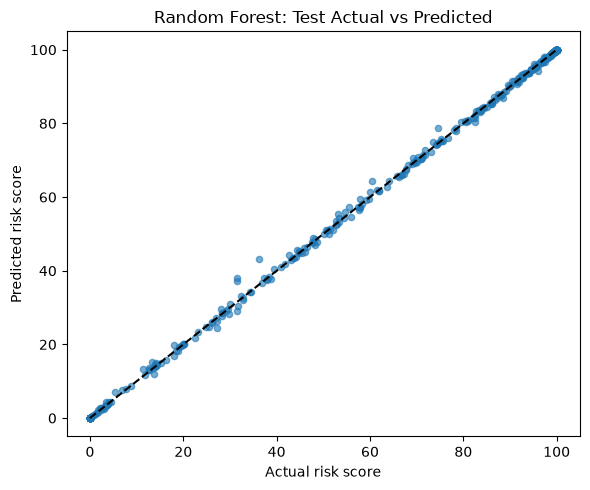

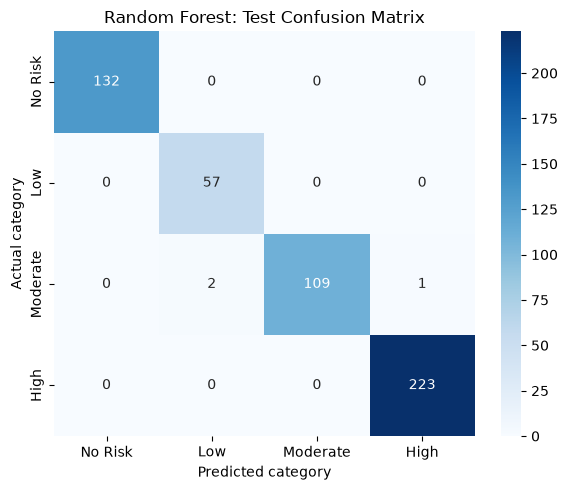

In [8]:
# Plot actual and predicted scores
evaluation_dir = PROJECT_ROOT / "reports/black_sigatoka/final_evaluation"
evaluation_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test, test_predictions, alpha=0.6, s=20)
ax.plot([0, 100], [0, 100], "--", color="black")
ax.set(xlabel="Actual risk score", ylabel="Predicted risk score",
       title="Random Forest: Test Actual vs Predicted")
fig.tight_layout()
fig.savefig(evaluation_dir / "test_actual_vs_predicted.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(test_confusion, annot=True, fmt="d", cmap="Blues",
            xticklabels=CATEGORY_ORDER, yticklabels=CATEGORY_ORDER, ax=ax)
ax.set(xlabel="Predicted category", ylabel="Actual category",
       title="Random Forest: Test Confusion Matrix")
fig.tight_layout()
fig.savefig(evaluation_dir / "test_confusion_matrix.png", dpi=150)
plt.show()


## 9. Example Predictions



In [9]:
# Show five test examples
examples = frames["test"].iloc[:5][FEATURES + [TARGET, "risk_level"]].copy()
examples["predicted_risk_score"] = test_predictions[:5]
examples["predicted_risk_level"] = predicted_categories.iloc[:5].to_numpy()
examples = examples.rename(columns={
    "air_temp_c": "Air temperature (C)",
    "estimated_leaf_wet": "Estimated leaf wetness",
    "consecutive_wetness_hours": "Consecutive wetness hours",
    TARGET: "Actual risk score",
    "risk_level": "Actual risk level",
    "predicted_risk_score": "Predicted risk score",
    "predicted_risk_level": "Predicted risk level",
})
display(examples)


,Air temperature (C),Estimated leaf wetness,Consecutive wetness hours,Actual risk score,Actual risk level,Predicted risk score,Predicted risk level
0,29.601,1,95,94.9136,High,94.887409,High
1,33.100,0,0,0.0000,No Risk,0.000000,No Risk
2,29.219,1,6,3.1670,Low,3.161771,Low
3,29.359,1,50,70.3079,Moderate,70.959659,Moderate
4,27.006,1,93,99.8187,High,99.779155,High


## 10. Final Results



In [10]:
# Compare validation and test results using saved validation reports
saved_classification = pd.read_csv(
    PROJECT_ROOT / "reports/black_sigatoka/random_forest/validation_classification_report.csv"
).set_index("category")
validation_accuracy = float(saved_classification.loc["accuracy", "f1_score"])
validation_macro_f1 = float(saved_classification.loc["macro avg", "f1_score"])
validation_table = pd.DataFrame([
    {"Metric": "MAE", "Validation": selected_row["validation_mae"], "Test": test_mae},
    {"Metric": "RMSE", "Validation": selected_row["validation_rmse"], "Test": test_rmse},
    {"Metric": "R-squared", "Validation": selected_row["validation_r2"], "Test": test_r2},
    {"Metric": "Category accuracy", "Validation": validation_accuracy, "Test": test_accuracy},
    {"Metric": "Macro F1-score", "Validation": validation_macro_f1,
     "Test": classification_table.loc["macro avg", "f1-score"]},
])
display(validation_table)

# Save evaluation tables and predictions
metric_rows = pd.DataFrame([
    {"metric": "MAE", "test_result": test_mae},
    {"metric": "RMSE", "test_result": test_rmse},
    {"metric": "R-squared", "test_result": test_r2},
    {"metric": "Category accuracy", "test_result": test_accuracy},
    {"metric": "Macro F1-score", "test_result": classification_table.loc["macro avg", "f1-score"]},
    {"metric": "Weighted F1-score", "test_result": classification_table.loc["weighted avg", "f1-score"]},
])
metric_rows.to_csv(evaluation_dir / "test_metrics.csv", index=False)
classification_table.rename_axis("risk_level").to_csv(evaluation_dir / "test_classification_report.csv")
pd.DataFrame(test_confusion, index=CATEGORY_ORDER, columns=CATEGORY_ORDER).rename_axis(
    "actual_category"
).to_csv(evaluation_dir / "test_confusion_matrix.csv")

prediction_table = frames["test"].copy()
prediction_table["raw_predicted_risk_score"] = test_predictions
prediction_table["predicted_risk_level"] = predicted_categories.to_numpy()
prediction_table.to_csv(evaluation_dir / "test_predictions.csv", index=False)

report_text = f"""# Final Random Forest Test Evaluation

## Scope
The saved Random Forest was selected before this one-time evaluation using validation MAE. The fixed model evaluated {len(y_test)} reserved synthetic test scenarios. It was not retrained, tuned, or changed. These are results against synthetic risk-score labels, not confirmed disease outcomes.

## Model and inputs
- Model: saved Random Forest at `Models/black_sigatoka/random_forest/random_forest_model.joblib`.
- Features: {", ".join(FEATURES)}; target: `{TARGET}`.
- Selected parameters: {metadata["selected_parameters"]}.
- Test data was not used for model selection.

## Regression metrics
{regression_table.to_string(index=False)}

Raw predictions ranged from {raw_min:.6f} to {raw_max:.6f}; out-of-range count: {int(out_of_range.sum())}. Regression metrics use unrounded raw predictions. Category labels use a separate 0-100 bounded copy.

## Risk-level metrics
Overall accuracy: {test_accuracy:.6f}. Incorrect category predictions: {incorrect_categories} of {len(y_test)}. Actual No Risk cases with positive raw predictions: {no_risk_positive_count}.

{risk_level_table.to_string()}

Confusion matrix (rows are actual; columns are predicted):
{pd.DataFrame(test_confusion, index=CATEGORY_ORDER, columns=CATEGORY_ORDER).to_string()}

## Validation and test comparison
{validation_table.to_string(index=False)}

Test results are reported for the frozen model and were not used to change model selection or settings. Differences from validation indicate performance variation on the reserved synthetic scenarios; they do not establish biological generalization.

## Limitations
Risk scores are synthetic, not confirmed Black Sigatoka infections or calibrated disease probabilities. The upstream score formula is unavailable and repeated feature combinations have small target differences. The wetness-duration input has unresolved prediction-time semantics; its availability from only past/current IoT readings is not verified. These results do not establish validated plantation IoT performance or future disease forecasting.
"""
(evaluation_dir / "Final_Test_Evaluation_Report.md").write_text(report_text, encoding="utf-8")

# Confirm datasets and saved model files are unchanged
hashes_after = {str(path.relative_to(PROJECT_ROOT)): sha256_file(path) for path in protected_paths}
assert hashes_after == hashes_before
print("Evaluation saved to:", evaluation_dir)
print("Dataset and saved model checksums are unchanged.")


,Metric,Validation,Test
0,MAE,0.363315,0.298249
1,RMSE,0.754338,0.732781
2,R-squared,0.999614,0.999690
3,Category accuracy,0.994664,0.994275
4,Macro F1-score,0.993559,0.991737


Evaluation saved to: C:\Users\HP\Desktop\ML training\reports\black_sigatoka\final_evaluation
Dataset and saved model checksums are unchanged.
